In [1]:
from src.utils import folders_creation,cracion_df_total,train_test_split_dfs
folders_creation()
df_total = cracion_df_total()
df_train, df_test = train_test_split_dfs()

Ya existe archivo total
 exist_total :True 
************************************ Comenzando split train test ************************************
Ya existe archivo train
Ya existe archivo test
exist train : True   and   exist_test :True  


# CANTIDAD DE LEIDOS POR LECTOR

In [ ]:
import matplotlib.pyplot as plt

# 1. Calcular la cantidad de libros leídos por lector
cantidad_leidos_por_lector = df_total.groupby('id_lector').size()

conteos = cantidad_leidos_por_lector.value_counts().sort_index()



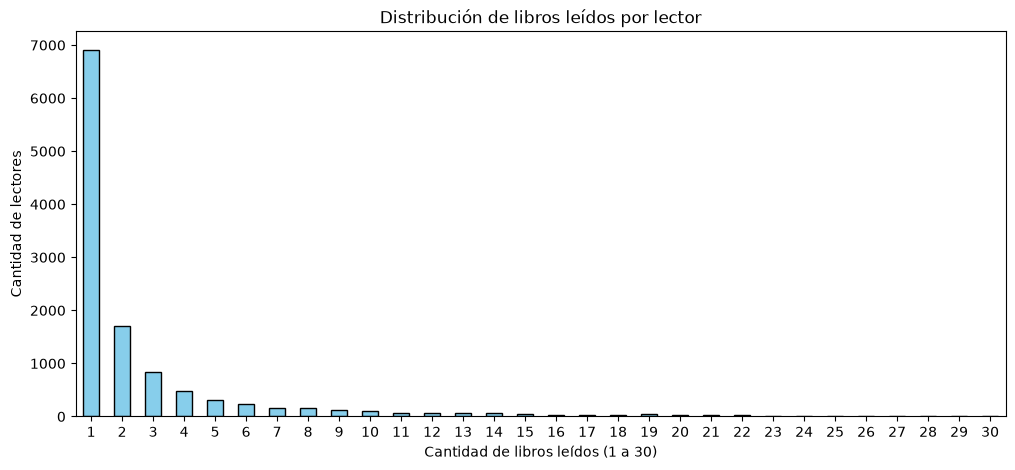

In [32]:
import matplotlib.pyplot as plt

# 1. Contar y ordenar
conteos = cantidad_leidos_por_lector.value_counts().sort_index()

# 2. Filtrar para excluir los valores atípicos extremos (ej. más de 50 libros)
conteos_filtrados = conteos[conteos.index <= 30]

# 3. Graficar con un tamaño más ancho (figsize)
conteos_filtrados.plot(kind='bar', color='skyblue', edgecolor='black', figsize=(12, 5))

plt.xlabel('Cantidad de libros leídos (1 a 30)')
plt.ylabel('Cantidad de lectores')
plt.title('Distribución de libros leídos por lector')

# Rotar las etiquetas a 0 grados para que queden horizontales
plt.xticks(rotation=0) 
plt.show()

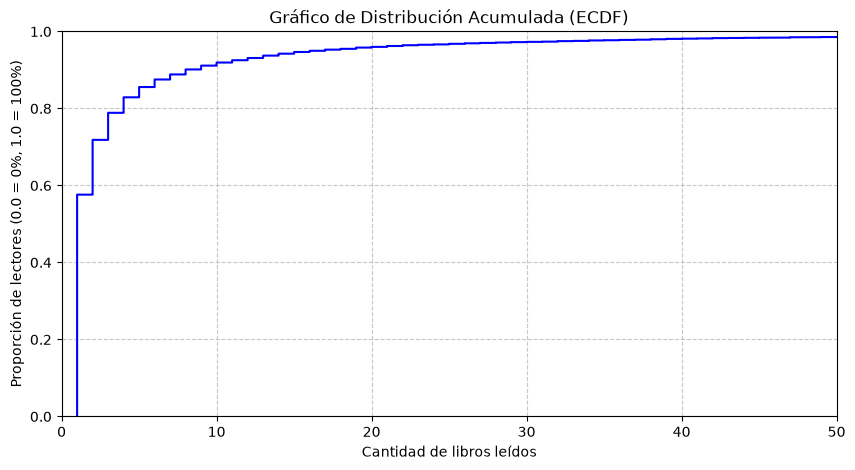

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# Genera la curva de distribución acumulada
sns.ecdfplot(data=cantidad_leidos_por_lector, color='blue')

plt.xlabel('Cantidad de libros leídos')
plt.ylabel('Proporción de lectores (0.0 = 0%, 1.0 = 100%)')
plt.title('Gráfico de Distribución Acumulada (ECDF)')

# Activar la grilla ayuda mucho a leer los porcentajes contra el eje X
plt.grid(True, linestyle='--', alpha=0.7) 
plt.xlim(0, 50) # Puedes limitar el eje X si la cola es muy larga
plt.show()

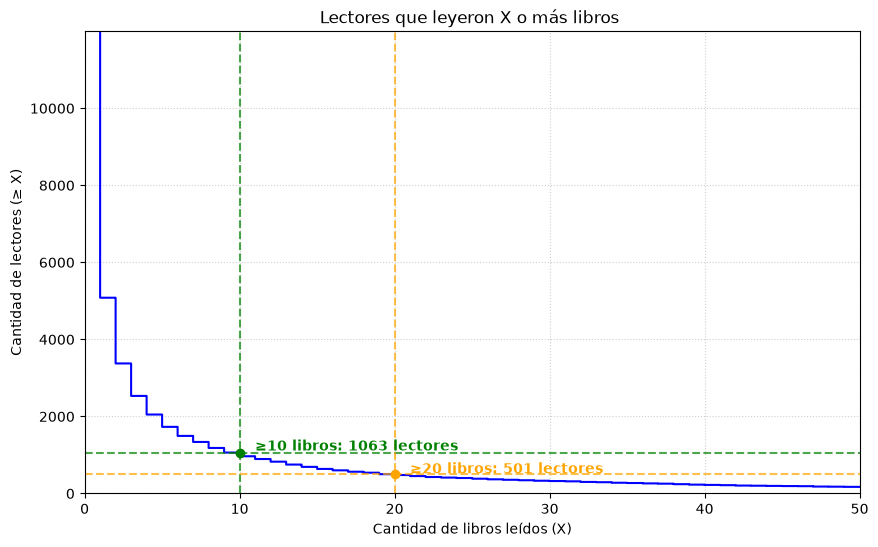

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# 1. Graficar la curva acumulada inversa
sns.ecdfplot(data=cantidad_leidos_por_lector, complementary=True, stat='count', color='blue')

# 2. Definir los puntos X que queremos marcar
puntos_x = [10,20]
colores = ['green', 'orange', 'red']

# 3. Iterar sobre cada punto para dibujar las líneas y el texto
for x, color in zip(puntos_x, colores):
    # Calcular cuántos lectores tienen >= X libros (el valor Y)
    y = (cantidad_leidos_por_lector >= x).sum()
    
    # Dibujar línea horizontal y vertical
    plt.axhline(y=y, color=color, linestyle='--', alpha=0.7)
    plt.axvline(x=x, color=color, linestyle='--', alpha=0.7)
    
    # Dibujar un punto en la intersección
    plt.plot(x, y, marker='o', color=color)
    
    # Agregar una etiqueta de texto con el número exacto
    plt.text(x + 1, y + (y * 0.05), f'≥{x} libros: {y} lectores', color=color, fontweight='bold')

# 4. Configurar el resto del gráfico
plt.xlabel('Cantidad de libros leídos (X)')
plt.ylabel('Cantidad de lectores (≥ X)')
plt.title('Lectores que leyeron X o más libros ')

plt.grid(True, linestyle=':', alpha=0.6) 
plt.xlim(0, 50) # Hacemos zoom hasta 50 libros para que se vea claro
plt.show()

In [29]:
conteos_filtrados.sum()

np.int64(501)

In [23]:
conteos.head(10)

1     6911
2     1706
3      843
4      483
5      320
6      235
7      157
8      156
9      119
10      96
Name: count, dtype: int64

In [3]:
df_train.shape

(25385, 4)

In [5]:
df_test.shape

(10020, 4)

In [8]:
df_test.id_lector.nunique()

501

In [9]:
501*20

10020

In [2]:
from src.feat_eng import pipeline_feature_engineering
df_total_feat= pipeline_feature_engineering(df_total)

=============== INICIANDO PIPELINE DE FEATURE ENGINEERING del state : entrenamiento ===============
-> Aplicando: volumen_lectura_por_lector para el estado : entrenamiento
-> Aplicando: rating_promedio_crudo_por_lector para el estado : entrenamiento
-> Aplicando: desviacion_estandar_rating_por_lector para el estado : entrenamiento
-> Aplicando: genero_favorito_por_lector para el estado : entrenamiento
-> Aplicando: ratio_libros_antiguos_vs_nuevos_por_lector para el estado : entrenamiento
-> Aplicando: rating_promedio_te_por_lector para el estado : entrenamiento
-> Aplicando: pct_autor_favorito_por_lector para el estado : entrenamiento
-> Aplicando: pct_genero_favorito_por_lector para el estado : entrenamiento
-> Aplicando: popularidad_count_por_libro y popularidad_rating_mean_por_libro para el estado : entrenamiento
-> Aplicando: rating_promedio_te_por_libro para el estado : entrenamiento
-> Aplicando: pct_lecturas_autor_candidato_por_par_libroylector para el estado : entrenamiento
-> 

In [4]:
import pandas as pd
pd.set_option('display.max_columns', None)

In [6]:
df_total_feat.id_libro.nunique()

19383

In [7]:
df_total_feat.ranking.nunique()

16581

In [5]:
df_total_feat.head()

,id_lector,id_libro,fecha_interaccion,rating,titulo,autor,genero_libro,anio_edicion,rating_promedio,cantidad_votos,volumenes,capitulos,ranking,en_emision,genero,vive_en,nacimiento,volumen_lectura_por_lector,rating_promedio_crudo_por_lector,desviacion_estandar_rating_por_lector,genero_favorito_por_lector,ratio_libros_antiguos_vs_nuevos_por_lector,rating_promedio_te_por_lector,pct_autor_favorito_por_lector,pct_genero_favorito_por_lector,popularidad_count_por_libro,popularidad_rating_mean_por_libro,rating_promedio_te_por_libro,pct_lecturas_autor_candidato_por_par_libroylector,pct_lecturas_genero_candidato_por_par_libroylector
0,corkboard,12,2014-09-10,9.0,Yotsuba&!,Kiyohiko AZUMA,Comedy,2003.0,4.405,3595.0,16.0,113.0,101.0,1.0,?,,NaN,15,5.733333,2.6762,Drama,2.2000,6.8146,0.133333,0.466667,9,9.5,7.4992,0.0667,0.2000
1,mchensan,12,2021-02-16,10.0,Yotsuba&!,Kiyohiko AZUMA,Comedy,2003.0,4.405,3595.0,16.0,113.0,101.0,1.0,?,,1997.0,9,6.611111,1.9405,Action,0.2500,7.0585,0.111111,0.888889,9,9.5,7.4992,0.1111,0.1111
2,ShibaYuko,12,2025-08-25,10.0,Yotsuba&!,Kiyohiko AZUMA,Comedy,2003.0,4.405,3595.0,16.0,113.0,101.0,1.0,M,Cemetery,2006.0,9,5.944444,2.7633,Drama,0.4286,6.9568,0.111111,0.333333,9,9.5,7.4992,0.1111,0.1111
3,guiguimauve,12,2021-07-26,9.0,Yotsuba&!,Kiyohiko AZUMA,Comedy,2003.0,4.405,3595.0,16.0,113.0,101.0,1.0,?,,2002.0,17,6.352941,1.8846,Comedy,17.0000,6.9396,0.058824,0.411765,9,9.5,7.4992,0.0588,0.4118
4,jjjhanghao,12,2021-03-24,10.0,Yotsuba&!,Kiyohiko AZUMA,Comedy,2003.0,4.405,3595.0,16.0,113.0,101.0,1.0,F,I live with my imaginary boyfriends.,NaN,5,9.900000,0.2000,Action,0.5000,7.3900,0.200000,0.600000,9,9.5,7.4992,0.2000,0.2000


In [9]:
df_train.head()

,id_lector,id_libro,rating,fecha_interaccion
0,0Pharaoh,88502.0,10.0,2025-12-26
1,0Pharaoh,78077.0,7.5,2025-12-29
2,0Pharaoh,111112.0,4.0,2026-05-02
0,135dragon,53482.0,9.0,2021-02-12
1,135dragon,23973.0,8.0,2021-02-13


In [13]:
df_test.groupby('id_lector').size()

id_lector
0Pharaoh         10
135dragon        10
35seali          10
707hairline      10
786Cookie        10
                 ..
ysaaaa           10
yujitegal        10
zdubwilly        10
zplaguez         10
zuhakaedehara    10
Length: 1063, dtype: int64

In [3]:
df_train_features = pipeline_feature_engineering(df_train, state='entrenamiento')

=============== INICIANDO PIPELINE DE FEATURE ENGINEERING del state : entrenamiento ===============
-> Aplicando: volumen_lectura_por_lector para el estado : entrenamiento
-> Aplicando: rating_promedio_crudo_por_lector para el estado : entrenamiento
-> Aplicando: desviacion_estandar_rating_por_lector para el estado : entrenamiento
-> Aplicando: genero_favorito_por_lector para el estado : entrenamiento
-> Aplicando: ratio_libros_antiguos_vs_nuevos_por_lector para el estado : entrenamiento
-> Aplicando: rating_promedio_te_por_lector para el estado : entrenamiento
-> Aplicando: pct_autor_favorito_por_lector para el estado : entrenamiento
-> Aplicando: pct_genero_favorito_por_lector para el estado : entrenamiento
-> Aplicando: popularidad_count_por_libro y popularidad_rating_mean_por_libro para el estado : entrenamiento
-> Aplicando: rating_promedio_te_por_libro para el estado : entrenamiento
-> Aplicando: pct_lecturas_autor_candidato_por_par_libroylector para el estado : entrenamiento
-> 

In [4]:
from src.filtrado_colaborativo import filtrado_colaborativo
m_lectores, m_libros = filtrado_colaborativo(state='entrenamiento')

Ya existe matriz de lectores para el state: entrenamiento
Ya existe matriz de libros para el state: entrenamiento


In [5]:
m_lectores

,generolector_?,generolector_F,generolector_M,generolector_O,pais_Argentina,pais_Australia,pais_Bahamas,pais_Belgium,pais_Brasil,pais_Brazil,...,autor_mini,autor_otro,anio_edicion_1960s,anio_edicion_1970s,anio_edicion_1980s,anio_edicion_1990s,anio_edicion_2000s,anio_edicion_2010s,anio_edicion_2020s,anio_edicion_viejos
id_lector,,,,,,,,,,,,,,,,,,,,,
0Pharaoh,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.400000,0.0,0.0,0.0,0.0,0.0,0.000000,0.716667,0.0
135dragon,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.788000,0.0,0.0,0.0,0.0,0.0,0.783333,0.900000,0.0
707hairline,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.621154,0.0,0.0,0.0,0.0,0.0,0.550769,0.649333,0.0
786Cookie,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.457143,0.0,0.0,0.0,0.0,0.3,0.592857,0.350000,0.3
8dajdn1lm114gsdggg,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.700000,0.0,0.0,0.0,0.0,0.0,1.000000,0.700000,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
yoohaaa,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.985000,0.0,0.0,0.0,0.0,0.0,0.981250,1.000000,0.0
ysaaaa,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.000000,0.0,0.0,0.0,0.0,0.0,1.000000,0.000000,0.0
zdubwilly,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.366667,0.0,0.0,0.0,0.0,0.3,0.000000,0.400000,0.0


In [5]:
from src.entrenar_ease import obtener_modelo_ease
modelo_ease = obtener_modelo_ease(df_train, state="entrenamiento")

-> Cargando modelo EASE desde caché: outputs/ease/modelo_ease_entrenamiento.pkl


In [6]:
from src.construccion_cache import construir_cache
cache = construir_cache(df_train_features ,modelo_lgbm_reg=None, modelo_lgbm_ranker=None,modelo_ease=modelo_ease, state='entrenamiento')


Construyendo Caché para Retrievals...
Caché  de entrenamiento construido con éxito.


In [15]:
import pickle

# Reemplaza 'tu_archivo.pkl' por la ruta real de tu archivo
ruta_archivo = 'outputs/cache_final/cache.pkl'

with open(ruta_archivo, 'rb') as archivo:
    cache = pickle.load(archivo)



In [3]:
cache.keys()

dict_keys(['df_train_features', 'dict_leidos_ratings', 'dict_leidos', 'populares_global', 'dict_libro_autor', 'dict_libro_genero', 'libros_por_autor', 'libros_por_genero', 'dict_lector_pais', 'populares_por_pais', 'populares_trending', 'dict_popularidad_score', 'media_global', 'jaccard_matrix', 'matriz_lectores', 'matriz_libros', 'modelo_ease'])

In [22]:
del cache['df_train_features']

In [23]:
del cache['jaccard_matrix'] 

In [24]:
del cache['dict_leidos_ratings'] 

In [25]:
del cache['matriz_lectores'] 

In [26]:
del cache['matriz_libros'] 

In [27]:
cache.keys()

dict_keys(['dict_leidos', 'populares_global', 'dict_libro_autor', 'dict_libro_genero', 'libros_por_autor', 'libros_por_genero', 'dict_lector_pais', 'populares_por_pais', 'populares_trending', 'dict_popularidad_score', 'media_global', 'modelo_ease'])

In [28]:
import pickle


# Ruta donde quieres guardar el archivo
ruta_archivo = 'outputs/cache_final/cache_liviano.pkl'

with open(ruta_archivo, 'wb') as archivo:
    pickle.dump(cache, archivo)

In [13]:
del cache['modelo_ease'] 

In [ ]:
cache['modelo_ease'].

In [20]:
cache['modelo_ease'].W = cache['modelo_ease'].W.astype('float16')

In [29]:
import pickle

# Reemplaza 'tu_archivo.pkl' por la ruta real de tu archivo
ruta_archivo = 'outputs/cache_final/cache_liviano.pkl'

with open(ruta_archivo, 'rb') as archivo:
    cache = pickle.load(archivo)



In [30]:
cache.keys()

dict_keys(['dict_leidos', 'populares_global', 'dict_libro_autor', 'dict_libro_genero', 'libros_por_autor', 'libros_por_genero', 'dict_lector_pais', 'populares_por_pais', 'populares_trending', 'dict_popularidad_score', 'media_global', 'modelo_ease'])

In [32]:
cache["modelo_ease"].X

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 55861 stored elements and shape (11290, 11042)>

# ANALISIS EXPLORATORIO 

In [2]:
import pandas as pd
df_total =pd.read_parquet("outputs/datasets/df_total.parquet")

In [3]:
df_total

,id_lector,id_libro,fecha_interaccion,rating
0,corkboard,12,2014-09-10,9.0
1,mchensan,12,2021-02-16,10.0
2,ShibaYuko,12,2025-08-25,10.0
3,guiguimauve,12,2021-07-26,9.0
4,jjjhanghao,12,2021-03-24,10.0
...,...,...,...,...
64197,tquinndo,118687,2026-11-07,8.0
64198,Shimejii,118695,2026-09-14,2.0
64199,Jemo,118695,2026-10-07,8.0
64200,Amzyy,118800,2026-09-22,9.0


In [4]:
import pandas as pd
import numpy as np

# 1. CÁLCULO DE DENSIDAD (Rápido y sin consumir memoria)
num_lectores = df_total['id_lector'].nunique()
num_libros = df_total['id_libro'].nunique()
num_interacciones = len(df_total)

# Total de celdas que tendría la matriz completa
celdas_totales = num_lectores * num_libros

densidad = num_interacciones / celdas_totales
densidad_porcentaje = densidad * 100

print(f"Lectores únicos (Usuarios): {num_lectores}")
print(f"Libros únicos (Items): {num_libros}")
print(f"Interacciones reales (Ratings): {num_interacciones}")
print(f"Celdas totales posibles: {celdas_totales}")
print(f"Densidad de la matriz: {densidad_porcentaje:.4f}%")

# 2. ARMAR LA MATRIZ (Si necesitas el objeto físico)
# Llenamos con 0 los mangas que un usuario no leyó
matriz_interacciones = df_total.pivot_table(
    index='id_lector', 
    columns='id_libro', 
    values='rating',
    fill_value=0
)

Lectores únicos (Usuarios): 11993
Libros únicos (Items): 19383
Interacciones reales (Ratings): 64202
Celdas totales posibles: 232460319
Densidad de la matriz: 0.0276%


In [7]:
import sqlite3
con=sqlite3.connect("dataset/recomendador_mangas.db")
query = """select * from interacciones i join libros l using(id_libro) join lectores lec using(id_lector)"""
interacciones = pd.read_sql_query(query , con)

In [8]:
interacciones.shape

(64202, 58)

In [10]:
pd.set_option('display.max_columns', None)

In [11]:
interacciones.head()

,id_interaccion,id_libro,id_lector,usuario_url,rating_story,rating_art,rating_characters,rating_overall,texto_review,fecha,fecha_interaccion,rating,titulo,url,sinopsis,tags,rating_promedio,cantidad_votos,staff,anio_publicacion,volumenes,capitulos,ranking,revista,titulos_alternativos,en_emision,procesado,imagen_url,reviews_procesadas,autor,genero,anio_edicion,id_usuario,usuario_url,fecha_registro,edad_genero,ubicacion,ultima_conexion,followers,following,mangas_leidos_total,mangas_read,mangas_reading,mangas_want,mangas_stalled,mangas_dropped,mangas_wont,animes_vistos_total,animes_watched,animes_watching,animes_want,animes_stalled,animes_dropped,animes_wont,edad,nacimiento,genero,vive_en
0,1,12,corkboard,https://www.anime-planet.com/users/corkboard,8.0,10.0,10.0,9.0,"There are no words to describe the simple, sum...","Sep 10, 2014 12:50 am",2014-09-10,9.0,Yotsuba&!,https://www.anime-planet.com/manga/yotsuba,"Meet Yotsuba Koiwai, the strangest little girl...","Comedy, Shounen, Slice of Life, Child Protagon...",4.405,3595,Kiyohiko AZUMA (Author & Artist),2003 - ?,16,113,101,Comic Dengeki Daioh,"Yotsuba to!, よつばと!",1,1,https://cdn.anime-planet.com/manga/primary/yot...,1,Kiyohiko AZUMA,Comedy,2003,1,https://www.anime-planet.com/users/corkboard,,? / ?,,Hidden,19,0,,95,22,55,8,10,6,,643,19,300,25,38,32,?,NaN,?,
1,2,12,mchensan,https://www.anime-planet.com/users/mchensan,10.0,10.0,10.0,10.0,"Yotsuba is the closest I can describe as a ""pe...","Feb 16, 2021 11:46 pm",2021-02-16,10.0,Yotsuba&!,https://www.anime-planet.com/manga/yotsuba,"Meet Yotsuba Koiwai, the strangest little girl...","Comedy, Shounen, Slice of Life, Child Protagon...",4.405,3595,Kiyohiko AZUMA (Author & Artist),2003 - ?,16,113,101,Comic Dengeki Daioh,"Yotsuba to!, よつばと!",1,1,https://cdn.anime-planet.com/manga/primary/yot...,1,Kiyohiko AZUMA,Comedy,2003,2,https://www.anime-planet.com/users/mchensan,,29 / ?,,"Mar 11, 2021",10,0,,9,16,0,0,3,0,,0,0,0,0,0,0,29,1997.0,?,
2,3,12,ShibaYuko,https://www.anime-planet.com/users/ShibaYuko,10.0,10.0,10.0,10.0,Yotsuba solo your favs. Literally the most com...,"Aug 25, 2025 4:26 pm",2025-08-25,10.0,Yotsuba&!,https://www.anime-planet.com/manga/yotsuba,"Meet Yotsuba Koiwai, the strangest little girl...","Comedy, Shounen, Slice of Life, Child Protagon...",4.405,3595,Kiyohiko AZUMA (Author & Artist),2003 - ?,16,113,101,Comic Dengeki Daioh,"Yotsuba to!, よつばと!",1,1,https://cdn.anime-planet.com/manga/primary/yot...,1,Kiyohiko AZUMA,Comedy,2003,3,https://www.anime-planet.com/users/ShibaYuko,,20 / M,Cemetery,15 hours ago,13,3,,330,4,287,10,13,12,,171,4,52,5,15,11,20,2006.0,M,Cemetery
3,4,12,guiguimauve,https://www.anime-planet.com/users/guiguimauve,7.0,6.0,10.0,9.0,This is one of the best comedy/slice of life m...,"Jul 26, 2021 10:03 pm",2021-07-26,9.0,Yotsuba&!,https://www.anime-planet.com/manga/yotsuba,"Meet Yotsuba Koiwai, the strangest little girl...","Comedy, Shounen, Slice of Life, Child Protagon...",4.405,3595,Kiyohiko AZUMA (Author & Artist),2003 - ?,16,113,101,Comic Dengeki Daioh,"Yotsuba to!, よつばと!",1,1,https://cdn.anime-planet.com/manga/primary/yot...,1,Kiyohiko AZUMA,Comedy,2003,4,https://www.anime-planet.com/users/guiguimauve,,24 / ?,,"Dec 23, 2025",0,0,,33,3,0,0,0,0,,0,0,0,0,0,0,24,2002.0,?,
4,5,12,jjjhanghao,https://www.anime-planet.com/users/jjjhanghao,9.0,9.0,10.0,10.0,I'm currently reading this and it's sooo whole...,"Mar 24, 2021 2:34 pm",2021-03-24,10.0,Yotsuba&!,https://www.anime-planet.com/manga/yotsuba,"Meet Yotsuba Koiwai, the strangest little girl...","Comedy, Shounen, Slice of Life, Child Protagon...",4.405,3595,Kiyohiko AZUMA (Author & Artist),2003 - ?,16,113,101,Comic Dengeki Daioh,"Yotsuba to!, よつばと!",1,1,https://cdn.anime-planet.com/manga/primary/yot...,1,Kiyohiko AZUMA,Comedy,2003,5,https://www.anime-planet.com/users/jjjhanghao,,? / F,I live with my imaginary boyfriends.,"May 22, 2026",14,14,,16,7,29,1,0,0,,102,3,75,2,2,1,?,NaN,F,I live with my imaginary boyfriends.


In [18]:
interacciones["ubicacion"].value_counts().head(15)


ubicacion
                                                 42999
Anytime, anywhere and at any place                2579
India                                             1405
United States                                      761
France                                             748
Take a guess~                                      500
In My Heavenly Bed! Somewhere In Scandinavia!      460
USA                                                434
NOwhere                                            397
Noneya Beezwax                                     364
The Piss Realm                                     361
Pseudo-Hueco Mundo                                 286
Somewhere Beautiful ❣️                             263
United states                                      258
coolies 😎                                          255
Name: count, dtype: int64

C:\Users\chris\AppData\Local\Temp\ipykernel_28616\2380778103.py:31: UserWarning: Glyph 10083 (\N{HEAVY HEART EXCLAMATION MARK ORNAMENT}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\chris\AppData\Local\Temp\ipykernel_28616\2380778103.py:31: UserWarning: Glyph 128526 (\N{SMILING FACE WITH SUNGLASSES}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\chris\Data_science\Ms Data Mining UBA\2do año\2do Cuatrimestre\Sistemas Recomendacion\Proyecto\manga-recommendation-system\.env_sr\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10083 (\N{HEAVY HEART EXCLAMATION MARK ORNAMENT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\chris\Data_science\Ms Data Mining UBA\2do año\2do Cuatrimestre\Sistemas Recomendacion\Proyecto\manga-recommendation-system\.env_sr\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128526 (\N{SMILING FACE WITH SUNGLASSES}) missing from font(s) Arial.
  fig.canvas.print_figure(by

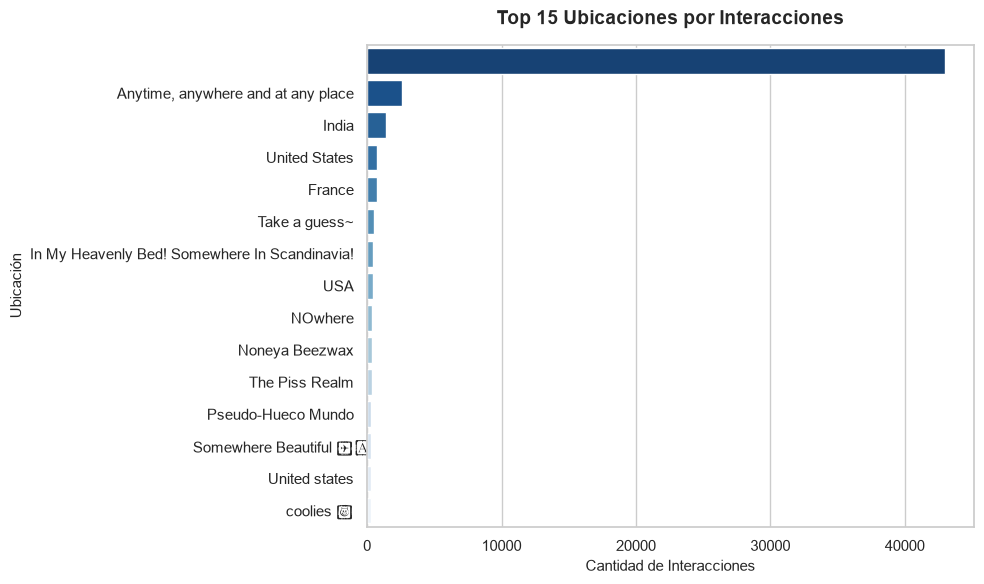

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Convertir el Value Counts en un DataFrame ordenado
top_ubicaciones = (
    interacciones["ubicacion"]
    .value_counts()
    .head(15)
    .reset_index()
)
top_ubicaciones.columns = ["ubicacion", "cantidad"]  # Asignar nombres limpios a las columnas

plt.figure(figsize=(10, 6))

# 2. Usar el parámetro 'data' oficial de Seaborn
sns.barplot(
    data=top_ubicaciones,
    x="cantidad",
    y="ubicacion",
    palette="Blues_r",
    hue="ubicacion",
    legend=False,
)

plt.title("Top 15 Ubicaciones por Interacciones", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Cantidad de Interacciones", fontsize=11)
plt.ylabel("Ubicación", fontsize=11)

plt.tight_layout()
plt.show()

<Axes: xlabel='rating_promedio', ylabel='Count'>

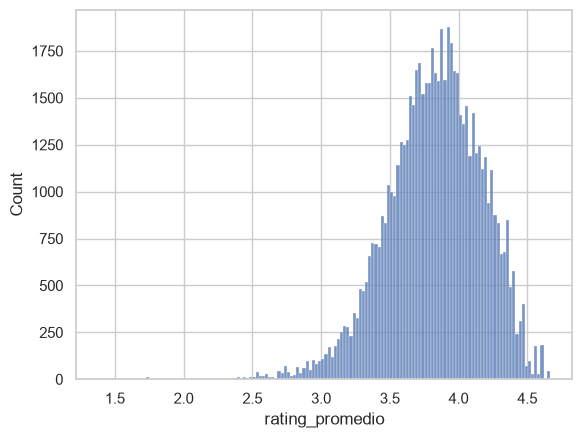

In [19]:
sns.histplot(interacciones.rating_promedio)

In [20]:
interacciones.rating_promedio.max()

np.float64(4.664)

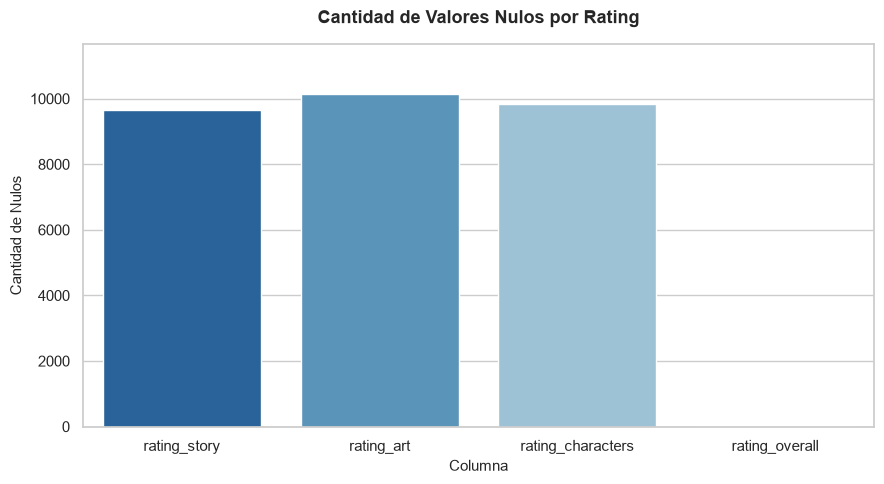

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Calcular los valores nulos de esas columnas
nulos = interacciones[
    ["rating_story", "rating_art", "rating_characters", "rating_overall"]
].isna().sum()

plt.figure(figsize=(9, 5))

# 2. Crear el gráfico guardando la referencia en 'ax'
ax = sns.barplot(
    x=nulos.index,
    y=nulos.values,
    palette="Blues_r",
    hue=nulos.index,
    legend=False,
)

# 3. Agregar los números arriba de cada barra automáticamente
#ax.bar_label(ax.containers[0], padding=3, fontsize=10, fontweight="bold")

# 4. Personalización y ajustes visuales
plt.title("Cantidad de Valores Nulos por Rating", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Columna", fontsize=11)
plt.ylabel("Cantidad de Nulos", fontsize=11)

# Opcional: expandir un poco el límite superior del eje Y para que los números no se corten
plt.ylim(0, nulos.max() * 1.15)

plt.tight_layout()
plt.show()

In [39]:
interacciones['Fecha interaccion calculada']=pd.to_datetime(interacciones.fecha).dt.date
interacciones['Fecha_inicio_mes'] = pd.to_datetime(interacciones['Fecha interaccion calculada']).dt.to_period('M').dt.to_timestamp().dt.date
interacciones['Anio'] = pd.to_datetime(interacciones['fecha']).dt.year

C:\Users\chris\AppData\Local\Temp\ipykernel_28616\1686144679.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  interacciones['Fecha interaccion calculada']=pd.to_datetime(interacciones.fecha).dt.date
C:\Users\chris\AppData\Local\Temp\ipykernel_28616\1686144679.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  interacciones['Anio'] = pd.to_datetime(interacciones['fecha']).dt.year


In [40]:
interacciones[['fecha','Fecha interaccion calculada','Fecha_inicio_mes','Anio']]

,fecha,Fecha interaccion calculada,Fecha_inicio_mes,Anio
0,"Sep 10, 2014 12:50 am",2014-09-10,2014-09-01,2014
1,"Feb 16, 2021 11:46 pm",2021-02-16,2021-02-01,2021
2,"Aug 25, 2025 4:26 pm",2025-08-25,2025-08-01,2025
3,"Jul 26, 2021 10:03 pm",2021-07-26,2021-07-01,2021
4,"Mar 24, 2021 2:34 pm",2021-03-24,2021-03-01,2021
...,...,...,...,...
64197,2026-11-09,2026-11-09,2026-11-01,2026
64198,2026-11-09,2026-11-09,2026-11-01,2026
64199,2026-11-09,2026-11-09,2026-11-01,2026
64200,2026-11-09,2026-11-09,2026-11-01,2026


In [43]:
interacciones.groupby("Anio").size()

Anio
2009       73
2010      223
2011      321
2012      281
2013      291
2014      227
2015      357
2016      427
2017      536
2018      594
2019     1247
2020     5415
2021     9465
2022    10771
2023     9501
2024     9251
2025     8637
2026     6585
dtype: int64

In [38]:
interacciones.groupby("Fecha_inicio_mes").size()[-15:]

Fecha_inicio_mes
2025-09-01    578
2025-10-01    646
2025-11-01    593
2025-12-01    670
2026-01-01    933
2026-02-01    571
2026-03-01    735
2026-04-01    665
2026-05-01    747
2026-06-01    673
2026-07-01    614
2026-08-01    618
2026-09-01    429
2026-10-01    490
2026-11-01    110
dtype: int64

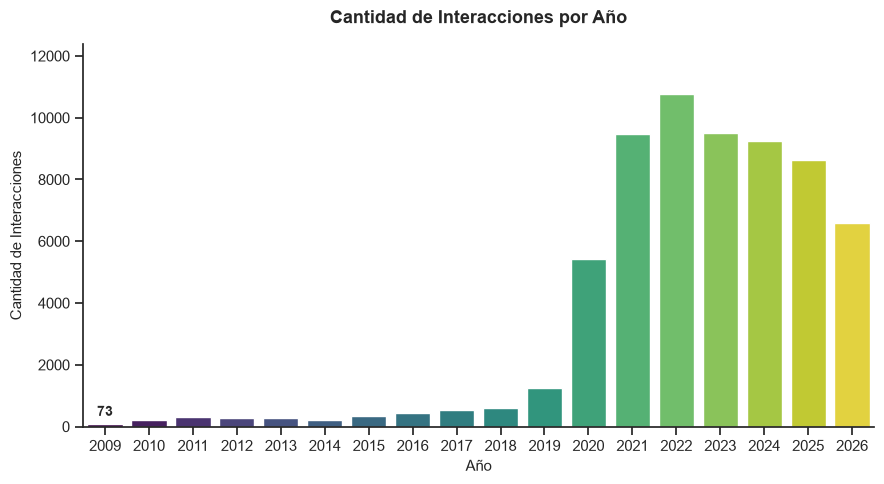

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configurar un tema estético más limpio (ej. 'ticks' con fondo blanco puro)
sns.set_theme(style="ticks")

# Agrupar por año
fechas = interacciones.groupby("Anio").size()

plt.figure(figsize=(9, 5))

# 2. Crear el gráfico con una paleta distinta (ej. "viridis" o "rocket")
ax = sns.barplot(
    x=fechas.index,
    y=fechas.values,
    palette="viridis",
    hue=fechas.index,
    legend=False,
)

# 3. Agregar los números arriba de cada barra automáticamente
ax.bar_label(ax.containers[0], padding=4, fontsize=10, fontweight="bold")

# 4. Personalización y títulos corregidos al contexto de años
plt.title("Cantidad de Interacciones por Año", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Año", fontsize=11)
plt.ylabel("Cantidad de Interacciones", fontsize=11)

# Ajustar límite superior del eje Y basándonos en 'fechas'
plt.ylim(0, fechas.max() * 1.15)

# Quitar bordes innecesarios (estilo minimalist / modern spine)
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

In [46]:
interacciones.columns

Index(['id_interaccion', 'id_libro', 'id_lector', 'usuario_url',
       'rating_story', 'rating_art', 'rating_characters', 'rating_overall',
       'texto_review', 'fecha', 'fecha_interaccion', 'rating', 'titulo', 'url',
       'sinopsis', 'tags', 'rating_promedio', 'cantidad_votos', 'staff',
       'anio_publicacion', 'volumenes', 'capitulos', 'ranking', 'revista',
       'titulos_alternativos', 'en_emision', 'procesado', 'imagen_url',
       'reviews_procesadas', 'autor', 'genero', 'anio_edicion', 'id_usuario',
       'usuario_url', 'fecha_registro', 'edad_genero', 'ubicacion',
       'ultima_conexion', 'followers', 'following', 'mangas_leidos_total',
       'mangas_read', 'mangas_reading', 'mangas_want', 'mangas_stalled',
       'mangas_dropped', 'mangas_wont', 'animes_vistos_total',
       'animes_watched', 'animes_watching', 'animes_want', 'animes_stalled',
       'animes_dropped', 'animes_wont', 'edad', 'nacimiento', 'genero',
       'vive_en', 'Fecha interaccion calculada', 'Fec

In [55]:
libros = pd.DataFrame(interacciones.groupby("titulo")["ranking"].mean()).reset_index()
libros.sort_values(by='ranking').head(5)

,titulo,ranking
11580,On the Way to Meet Mom,1.0
16028,The Greatest Magicmaster's Retirement Plan: Th...,1.0
14252,Solo Leveling,2.0
5403,"Got Dropped into a Ghost Story, Still Gotta Wo...",3.0
1876,Berserk,4.0
